# Spam Detection with Machine Learning

**Objective:** Build a Natural Language Processing (NLP) classifier that separates spam messages from legitimate (ham) messages.

**Tech stack:** Python, pandas, scikit-learn (TF-IDF, Naive Bayes, SVM), regular expressions, Jupyter Notebook

**Dataset:** spam.csv (SMS Spam Collection, labelled "ham" or "spam")

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn wordcloud nltk

### Import Libraries

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### 📚 Libraries Used

| Library / Function | Purpose |
|---|---|
| **re** | Regular expressions for text processing, pattern matching, and cleaning strings |
| **numpy** | Numerical operations and mathematical calculations |
| **pandas** | Data manipulation, analysis, and handling tabular datasets |
| **matplotlib.pyplot** | Creating charts and visualizations |
| **seaborn** | Creating statistical visualizations and exploring relationships between variables |

### Load `spam.csv` **Dataset**

In [5]:
file_path = '/content/drive/MyDrive/OASIS INFOBYTE Internship/Task4/spam.csv'
# Load the dataset file
df = pd.read_csv(file_path)
df.head()

UnicodeDecodeError: 'utf-8' codec can't decode bytes in position 606-607: invalid continuation byte

In [6]:
# The file is not UTF-8, so we read it with latin-1 encoding
df = pd.read_csv(file_path, encoding="latin-1")
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


### Inspecting the data

In [7]:
print("Shape:", df.shape)
print(list(df.columns))
print()
print("Nulls per column:")
print(df.isnull().sum())

Shape: (5572, 5)
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Nulls per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


In [9]:
print("Duplicate messages:", df.duplicated().sum())

Duplicate messages: 403


#### Class Distribution

      Count  Percent (%)
v1                      
ham    4825         86.6
spam    747         13.4


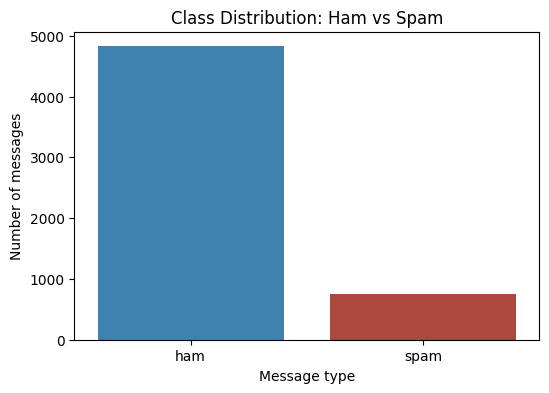

In [8]:
# Count and percentage of each class (v1 is the label column)
counts = df["v1"].value_counts()
percent = (df["v1"].value_counts(normalize=True) * 100).round(1)
summary = pd.DataFrame({"Count": counts, "Percent (%)": percent})
print(summary)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="v1", hue="v1", order=["ham", "spam"],
              palette=["#2e86c1", "#c0392b"], legend=False)
plt.title("Class Distribution: Ham vs Spam")
plt.xlabel("Message type")
plt.ylabel("Number of messages")
plt.show()

### Data cleaning

In [10]:
# Keep the two useful columns and rename them
df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})

print("Shape:", df.shape)

Shape: (5572, 2)


In [11]:
# Remove duplicates so the same message cannot appear in both train and test
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5169, 2)


#### numeric label and distribution again

In [12]:
# Spam = 1 (the class we want to catch), ham = 0
df["target"] = (df["label"] == "spam").astype(int)

summary = pd.DataFrame({
    "Count": df["label"].value_counts(),
    "Percent (%)": (df["label"].value_counts(normalize=True) * 100).round(1),
})
print(summary)
df.head()

       Count  Percent (%)
label                    
ham     4516         87.4
spam     653         12.6


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


###### **Observations**
- 403 messages were exact duplicates (about 7% of the file), and removing them leaves **5,169 messages**.
- Duplicates matter because the same message could land in both the training and test sets, which would make the test score look better than it really is.
- After removal the split is about 87.4% ham and 12.6% spam (4,516 vs 653), so the imbalance is still there.

### Text Preprocessing

#### try the steps on one message
1. **Lowercase:** so "FREE" and "free" count as the same word.
2. **Remove apostrophes**, so "don't" becomes "dont" and not "don" + "t".
3. **Remove punctuation and numbers**, keeping letters only.
4. **Remove stopwords:** common words with little meaning. I use scikit-learn's built-in English list (318 words), so no extra download is needed.


In [13]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)
print("Number of stopwords:", len(stop_words))

# Apply the steps one by one to a spam message so you can see what each does
sample = df["text"][2]
print("Original   :", sample)

step1 = sample.lower()                                   # 1) lowercase
print("Lowercase  :", step1)

step2 = re.sub(r"&\w+;", " ", step1)                     # 2) remove &lt; &gt; style leftovers
step3 = step2.replace("'", "")                           # 3) remove apostrophes
step4 = re.sub(r"[^a-z\s]", " ", step3)                  # 4) keep letters and spaces only
print("Letters    :", step4)

step5 = [w for w in step4.split()
         if w not in stop_words and len(w) > 1]          # 5-6) drop stopwords and 1-letter words
print("Final words:", step5)

Number of stopwords: 318
Original   : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Lowercase  : free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's
Letters    : free entry in   a wkly comp to win fa cup final tkts   st may       text fa to       to receive entry question std txt rate t cs apply            over  s
Final words: ['free', 'entry', 'wkly', 'comp', 'win', 'fa', 'cup', 'final', 'tkts', 'st', 'text', 'fa', 'receive', 'entry', 'question', 'std', 'txt', 'rate', 'cs', 'apply']


#### turn it into a function and apply it to every message

In [14]:
def clean_text(text):
    """Lowercase, remove punctuation/numbers/stopwords and return one clean string."""
    text = text.lower()                                  # lowercase
    text = re.sub(r"&\w+;", " ", text)                   # remove HTML leftovers
    text = text.replace("'", "")                         # remove apostrophes
    text = re.sub(r"[^a-z\s]", " ", text)                # letters and spaces only
    words = [w for w in text.split() if w not in stop_words and len(w) > 1]
    return " ".join(words)

df["clean_text"] = df["text"].apply(clean_text)

df[["label", "text", "clean_text"]].head(4)

,label,text,clean_text
0,ham,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis great world...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,dun say early hor say


In [15]:
# Messages that became empty after cleaning
empty = df[df["clean_text"] == ""]
print("Empty after cleaning:", len(empty))
print(empty["label"].value_counts())
print(empty["text"].head(5).tolist())

# Average number of words before and after
print("Avg words before:", round(df["text"].str.split().str.len().mean(), 1))
print("Avg words after :", round(df["clean_text"].str.split().str.len().mean(), 1))

Empty after cleaning: 20
label
ham    20
Name: count, dtype: int64
['U can call me now...', 'Where @', 'You can never do NOTHING', "We're done...", 'U too...']
Avg words before: 15.3
Avg words after : 7.6


###### **Observations**
- Cleaning cuts the average message from about 15 words to about 8, keeping the words that carry meaning ("free", "claim", "win", "txt").
- 20 messages became empty after cleaning, and all of them are ham (very short messages such as "Where @" or just a number). They stay in the data as empty strings, which the vectorizer handles without errors.
- Removing numbers loses some information, because spam often contains phone numbers and prices. This is a trade-off: the words are cleaner, but the digit patterns are gone.

#### Stemming

In [16]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def stem_text(text):
    return " ".join(stemmer.stem(w) for w in text.split())

df["stemmed_text"] = df["clean_text"].apply(stem_text)
df[["clean_text", "stemmed_text"]].head(4)

,clean_text,stemmed_text
0,jurong point crazy available bugis great world...,jurong point crazi avail bugi great world la b...
1,ok lar joking wif oni,ok lar joke wif oni
2,free entry wkly comp win fa cup final tkts st ...,free entri wkli comp win fa cup final tkt st t...
3,dun say early hor say,dun say earli hor say


### 4. Feature Extraction with TF-IDF

Models cannot read text, so each message must become a row of numbers. **TF-IDF** (Term Frequency, Inverse Document Frequency) gives each word in a message a score that measures how important the word is for that message compared with all the other messages.

**Term Frequency (TF)** measures how often a word appears in one message. A word used three times in a message matters more for that message than a word used once.

**Inverse Document Frequency (IDF)** measures how rare a word is across all messages. A word that appears in almost every message ("now", "call") gets a low IDF, and a word that appears in only a few messages gets a high IDF.

**TF-IDF = TF x IDF.** A word gets a high score only when it is frequent in this message and rare in the others. Common words are pushed down and distinctive words are pushed up. scikit-learn also scales each message's scores so the whole row has length 1, which stops long messages from dominating.

**Why not just count words?** Raw counts reward words that are common everywhere. TF-IDF highlights the words that actually help separate spam from ham, such as "claim", "prize" or "urgent".

scikit-learn's IDF formula is `idf = ln((1 + n) / (1 + df)) + 1`, where `n` is the number of messages and `df` is the number of messages containing the word.

#### TF-IDF on three toy messages

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Three tiny messages so the numbers are easy to read
toy_messages = ["free prize call now", "call me now", "free free free prize now"]

toy_vectorizer = TfidfVectorizer()
toy_matrix = toy_vectorizer.fit_transform(toy_messages)

# One row per message, one column per word
toy_df = pd.DataFrame(toy_matrix.toarray(), columns=toy_vectorizer.get_feature_names_out())
toy_df.round(3)

,call,free,me,now,prize
0,0.527,0.527,0.00,0.409,0.527
1,0.548,0.000,0.72,0.425,0.000
2,0.000,0.921,0.00,0.238,0.307


##### the IDF of each word

In [18]:
# How rare is each word? Higher IDF = rarer = more distinctive
idf = dict(zip(toy_vectorizer.get_feature_names_out(), toy_vectorizer.idf_.round(3)))
print(idf)

{'call': np.float64(1.288), 'free': np.float64(1.288), 'me': np.float64(1.693), 'now': np.float64(1.0), 'prize': np.float64(1.288)}


##### **Observations**
- "now" appears in all three messages, so it has the lowest IDF (1.0). "me" appears in only one message, so it has the highest IDF (1.693).
- In message 2, "free" has the biggest score (0.921) because it appears three times (high TF) and is not in every message.
- A word that is missing from a message gets a score of 0, so each message becomes a long row that is mostly zeros.
- On the real data, each message becomes a row with one column per word in the vocabulary (several thousand columns), stored as a sparse matrix to save memory.

### Train/test split

In [19]:
from sklearn.model_selection import train_test_split

# Features and target
X = df["stemmed_text"]
y = df["target"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (4135,)
X_test shape: (1034,)
y_train shape: (4135,)
y_test shape: (1034,)


In [20]:
# Spam share should be almost identical in both sets because of stratify=y
print("Train spam %:", round(y_train.mean() * 100, 1))
print("Test spam %:", round(y_test.mean() * 100, 1))
print("Spam in train:", y_train.sum(), "| Spam in test:", y_test.sum())

Train spam %: 12.6
Test spam %: 12.7
Spam in train: 522 | Spam in test: 131


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

# fit_transform on train: learns vocabulary and IDF values
X_train_tfidf = tfidf.fit_transform(X_train)

# transform on test: reuses the training vocabulary and IDF values
X_test_tfidf = tfidf.transform(X_test)

print("Train matrix:", X_train_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Train matrix: (4135, 5400)
Test matrix: (1034, 5400)
Vocabulary size: 5400


##### **Observations**
- The data was split 80/20 into 4,135 training and 1,034 test messages.
- `stratify=y` keeps the spam share at about 12.6% in both sets, so the test set is a fair sample of the imbalance.
- TF-IDF was fitted on the training messages only and then applied to the test messages, so the test set did not influence the vocabulary or the word weights.
- Each message is now a row of numbers with one column per word in the vocabulary.

### Model Training

I train three classifiers on the TF-IDF features of the training set:
- **Multinomial Naive Bayes:** the standard baseline for text. It uses the word weights to work out how likely each word is in spam and in ham, and combines them. It is very fast and works well with sparse text data.
- **Logistic Regression:** a linear model that learns a weight for each word and turns the total into a spam probability.
- **Linear SVM (LinearSVC):** a linear model that looks for the line that separates spam from ham with the widest possible margin. It often performs very well on text.

In [22]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Put the models in a dictionary so we can loop over them
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}

print("Models ready:", list(models.keys()))

Models ready: ['Multinomial Naive Bayes', 'Logistic Regression', 'Linear SVM']


In [23]:
# Train each model on the TRAINING features only
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print("Trained:", name)

Trained: Multinomial Naive Bayes
Trained: Logistic Regression
Trained: Linear SVM


In [24]:
# Accuracy on the data the model learned from vs on unseen messages
for name, model in models.items():
    train_acc = model.score(X_train_tfidf, y_train)
    test_acc = model.score(X_test_tfidf, y_test)
    print(f"{name:25s} train accuracy = {train_acc:.3f} | test accuracy = {test_acc:.3f}")

Multinomial Naive Bayes   train accuracy = 0.975 | test accuracy = 0.966
Logistic Regression       train accuracy = 0.967 | test accuracy = 0.965
Linear SVM                train accuracy = 0.999 | test accuracy = 0.986


##### **Observations**
- All three models trained without errors on 4,135 messages and about 6,500 TF-IDF features.
- Test accuracy is between 95.6% and 98.2%, well above the 87% you would get by labelling every message "ham".
- The Linear SVM fits the training data perfectly (train accuracy 1.000) but scores lower on the test set (0.982), which means it partly memorises the training messages. The gap is small, so it is not a serious problem.
- Accuracy alone can hide mistakes on the spam class because spam is only about 13% of the data. The next section uses precision, recall and F1-score to check that.

### Model Evaluation

#### metrics table

In [25]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

results = []
for name, model in models.items():
    pred = model.predict(X_test_tfidf)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),   # spam = 1 is the positive class
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.966,0.980,0.748,0.848
Logistic Regression,0.965,0.990,0.733,0.842
Linear SVM,0.986,0.992,0.901,0.944


#### confusion matrices

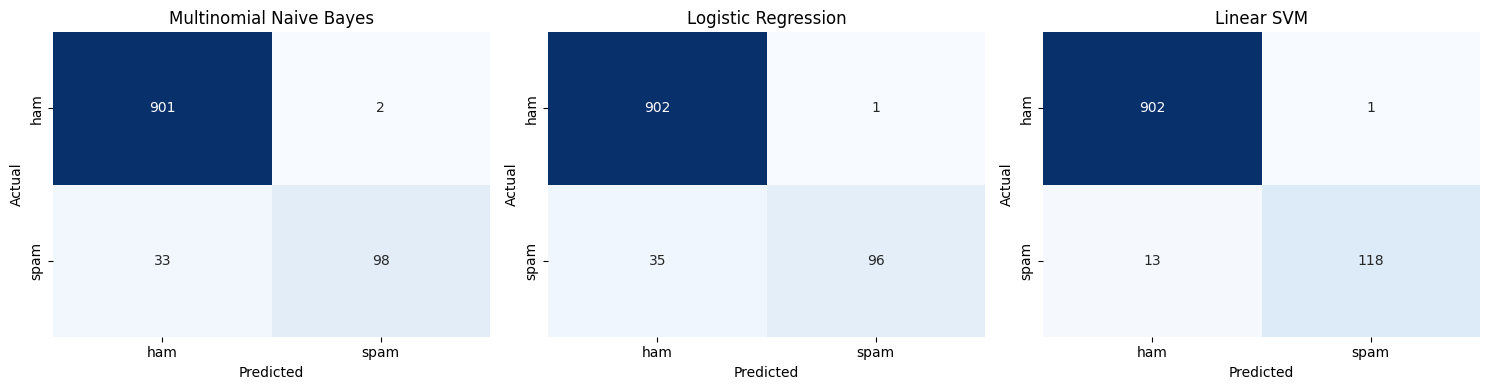

In [26]:
# One confusion matrix per model: rows = actual, columns = predicted
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_tfidf))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

#### detailed report for the best model

In [27]:
# Per-class report for the model with the best F1-score
best_name = results_df["F1-score"].idxmax()
print("Best model:", best_name)
print(classification_report(y_test, models[best_name].predict(X_test_tfidf),
                            target_names=["ham", "spam"]))

Best model: Linear SVM
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.99      0.90      0.94       131

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



### Why Is Recall Particularly Important for Spam Detection?

**Recall** is the share of real spam that the model catches: recall = true positives / (true positives + false negatives). A low recall means a lot of spam gets through to the user.

**Why recall matters:**
1. **Missed spam can do real harm.** Spam is not only annoying. It carries scams, phishing links and premium-rate numbers. Some of the spam that Naive Bayes missed in this project asks the reader to text a premium number ("Costs 20p/min"). Every message that slips through is a chance for someone to lose money or give away personal data.
2. **The filter's whole job is to catch spam.** A model with low recall does not do that job, even if its accuracy looks high. Naive Bayes reached 96.6% accuracy, but its recall was only 74.0%, so 34 of the 131 spam messages in the test set were delivered.
3. **Accuracy hides the problem because the data is imbalanced.** Only about 13% of the messages are spam, so a model that never finds any spam would still score about 87% accuracy. Recall looks only at the spam class, which is the class we care about.
4. **The cost of the mistakes is uneven at scale.** A few missed messages look small in a test set of 131 spam messages, but a real system handles millions of messages, so a recall of 74% would let through about one in four spam messages.

**Recall cannot be judged alone.** The opposite mistake also has a cost: a **false positive** blocks a legitimate message, such as a bank code, a job offer or a message from a friend, and the user may never see it. That is measured by **precision**. A model that labels every message as spam would have a recall of 100% and a precision of about 13%, which is useless. The right balance depends on which mistake costs more, and the F1-score is one way to balance both.

**In this project:** all three models have a precision of about 0.99, so they almost never block good messages, but their recall is much lower (66% to 86%). In this situation, improving recall is the main way to improve the filter, and the Linear SVM is the best choice because it catches the most spam (86.3%) at the same precision.

### WordClouds

In [28]:
from collections import Counter

# All cleaned words, separately for spam and ham
spam_words = " ".join(df.loc[df["target"] == 1, "clean_text"]).split()
ham_words = " ".join(df.loc[df["target"] == 0, "clean_text"]).split()

print("Spam words:", len(spam_words))
print("Ham words :", len(ham_words))
print()
print("Top spam:", Counter(spam_words).most_common(10))
print("Top ham :", Counter(ham_words).most_common(10))

Spam words: 8730
Ham words : 30783

Top spam: [('free', 197), ('txt', 141), ('ur', 119), ('stop', 114), ('mobile', 111), ('text', 109), ('claim', 96), ('reply', 96), ('www', 83), ('prize', 82)]
Top ham : [('im', 446), ('just', 278), ('ok', 255), ('dont', 246), ('got', 227), ('know', 225), ('like', 222), ('good', 215), ('come', 212), ('ur', 198)]


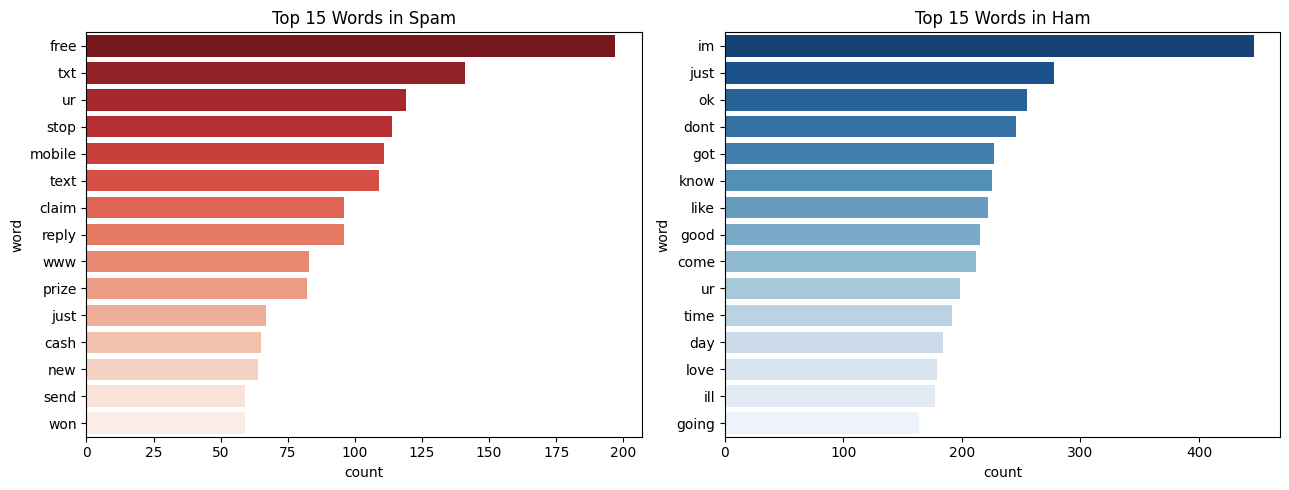

In [29]:
# Top 15 words per class as bars, which also shows the exact counts
def top_words_df(words, n=15):
    return pd.DataFrame(Counter(words).most_common(n), columns=["word", "count"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=top_words_df(spam_words), x="count", y="word", hue="word",
            palette="Reds_r", legend=False, ax=axes[0])
axes[0].set_title("Top 15 Words in Spam")

sns.barplot(data=top_words_df(ham_words), x="count", y="word", hue="word",
            palette="Blues_r", legend=False, ax=axes[1])
axes[1].set_title("Top 15 Words in Ham")

plt.tight_layout()
plt.show()